# Quantum methods for energy, 2026: a categorisation
40 entries: the 34 in our sources doc (challenges, conferences, papers, repos) and 6 marked supplements we found while reading them (S1-S3 forecasting, S4-S6 samplers). Each was read in the paper or repo itself. Three axes: **paradigm** (the 2026 unit-commitment survey's split: annealing / variational-hybrid / quantum-inspired, extended with non-variational gate, quantum ML and linear algebra), **hybrid pattern** (how quantum and classical share the work) and **pipeline stage** (where it would enter KratTrade: forecast, gate A/B day-ahead, gate C real time).

In [1]:
import pathlib, numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.patches as mp
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'research' else pathlib.Path.cwd()
M = pd.read_csv(ROOT / 'research' / 'methods.csv', dtype=str).fillna('')
SURF, INK, INK2, GRID, GREY = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df', '#9a9893'
PAR = {'Quantum annealing': '#eb6834', 'Gate variational': '#2a78d6', 'Gate non-variational': '#eda100', 'Quantum ML': '#e87ba4',
       'Continuous / linear algebra': '#6250d6', 'Multi-paradigm (challenge)': '#c9c7c1', 'Out of scope': '#e4e3df'}  # dataviz slots, fixed order
PG = {'Monolithic': 'Monolithic QUBO', 'Monolithic + discard invalid shots': 'Monolithic QUBO',
      'Binaries on QPU + classical continuous': 'Binaries on QPU, MW classical',
      'Decomposition': 'Decomposition', 'Decomposition (time hierarchy)': 'Decomposition', 'Rolling horizon': 'Decomposition',
      'Rolling horizon + classical checks': 'Decomposition', 'Pre/post-processing': 'Pre / post-processing, warm start',
      'Warm start': 'Pre / post-processing, warm start', 'Warm start (time-averaged stage)': 'Pre / post-processing, warm start',
      'Iterative bias update': 'Pre / post-processing, warm start', 'Hybrid sampler (QPU proposes / CPU accepts)': 'QPU sampler, CPU accepts',
      'Learned surrogate': 'Learned model (QML)', 'Learned policy': 'Learned model (QML)', 'Penalty into continuous cost': 'Continuous relaxation', 'n.a.': 'n.a.'}
M['group'] = M.pattern.map(PG)
plt.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF, 'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2,
                     'ytick.color': INK2, 'text.color': INK, 'font.size': 11, 'axes.grid': True, 'grid.color': GRID,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False, 'figure.dpi': 110})
print(M.source.value_counts().to_dict())

{'paper': 11, 'conference': 9, 'challenge': 8, 'repo': 6, 'supplement': 6}


## 1 · The taxonomy
Paradigm, then hybrid pattern, then each entry. Gate-variational methods dominate (18 of 40), and most of them hand part of the problem to a classical solver.

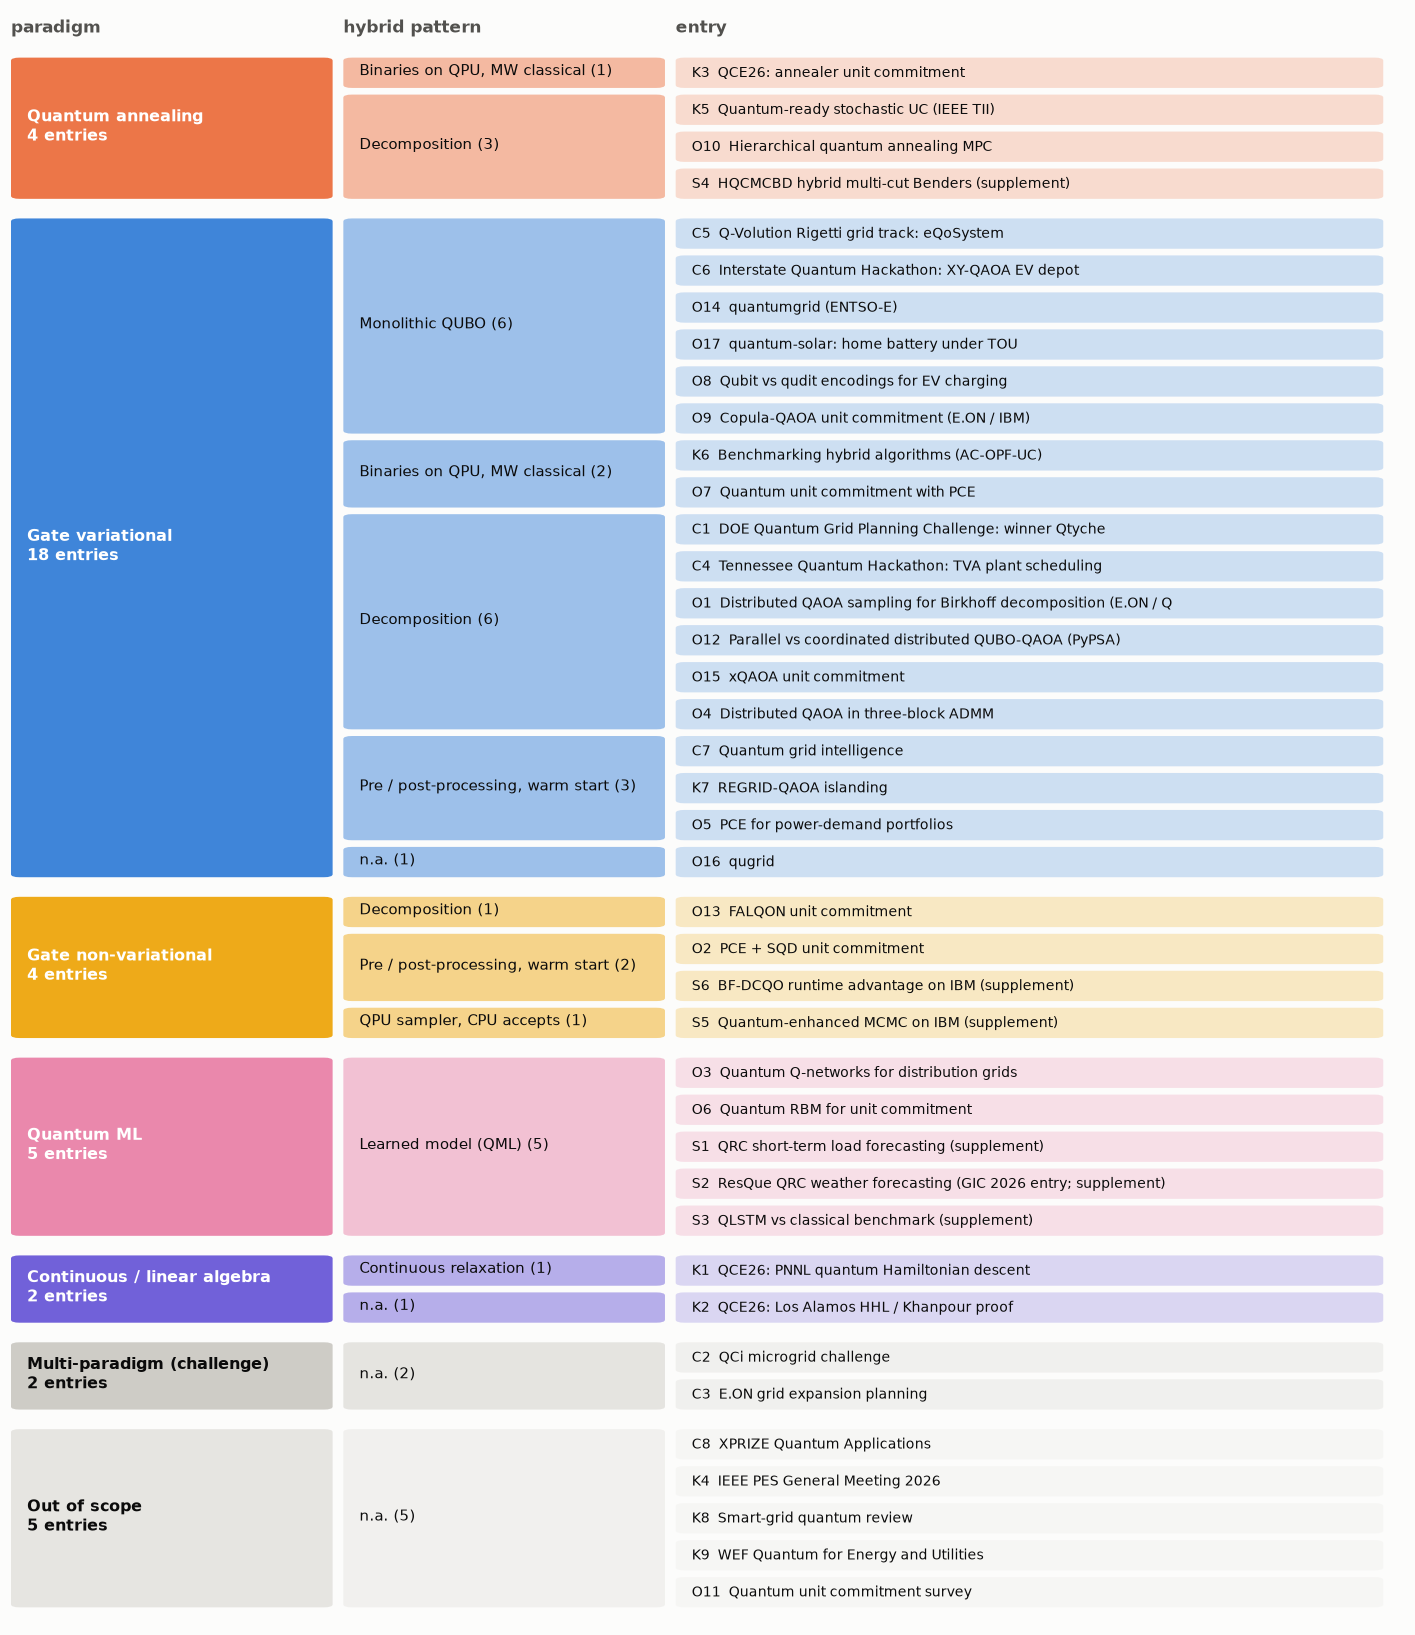

In [2]:
order = [p for p in PAR if p in set(M.paradigm)]
gorder = ['Monolithic QUBO', 'Binaries on QPU, MW classical', 'Decomposition', 'Pre / post-processing, warm start', 'QPU sampler, CPU accepts',
          'Learned model (QML)', 'Continuous relaxation', 'n.a.']
T = M.assign(po=M.paradigm.map(order.index), go=M.group.map(gorder.index)).sort_values(['po', 'go', 'id']).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(13, 15)); ax.axis('off'); y = 0; H = 1.0
for p, gp in T.groupby('po', sort=True):
    par = order[p]; y0 = y
    for g, gg in gp.groupby('go', sort=True):
        y1 = y
        for _, r in gg.iterrows():
            ax.add_patch(mp.FancyBboxPatch((6.2, -y - .9), 6.6, .82, boxstyle='round,pad=0,rounding_size=.08', fc=PAR[par], alpha=.22, ec='none'))
            ax.text(6.35, -y - .5, f"{r.id}  {r['name'][:62]}", va='center', fontsize=9)
            y += H
        ax.add_patch(mp.FancyBboxPatch((3.1, -y + .1), 3.0, y - y1 - .18, boxstyle='round,pad=0,rounding_size=.08', fc=PAR[par], alpha=.45, ec='none'))
        ax.text(3.25, -(y1 + y) / 2 + .05, f"{gorder[g]} ({len(gg)})", va='center', fontsize=9.5)
    ax.add_patch(mp.FancyBboxPatch((0, -y + .1), 3.0, y - y0 - .18, boxstyle='round,pad=0,rounding_size=.08', fc=PAR[par], alpha=.9, ec='none'))
    ax.text(.15, -(y0 + y) / 2 + .05, f"{par}\n{len(gp)} entries", va='center', fontsize=10.5, color='white' if par not in ('Multi-paradigm (challenge)', 'Out of scope') else INK, weight='bold')
    y += .35
for x, t in ((0, 'paradigm'), (3.1, 'hybrid pattern'), (6.2, 'entry')):
    ax.text(x, .6, t, fontsize=11, color=INK2, weight='bold')
ax.set_xlim(0, 13); ax.set_ylim(-y, 1.2); plt.tight_layout(); plt.show()

## 2 · Where each method would enter KratTrade
Lanes follow our pipeline: forecast inputs, then the gate A/B day-ahead decision, then gate C real-time control. The doc has **no quantum forecasting entry**: the forecasting lane is filled only by supplements S1-S3 and the qRBM, which predicts decisions rather than prices.

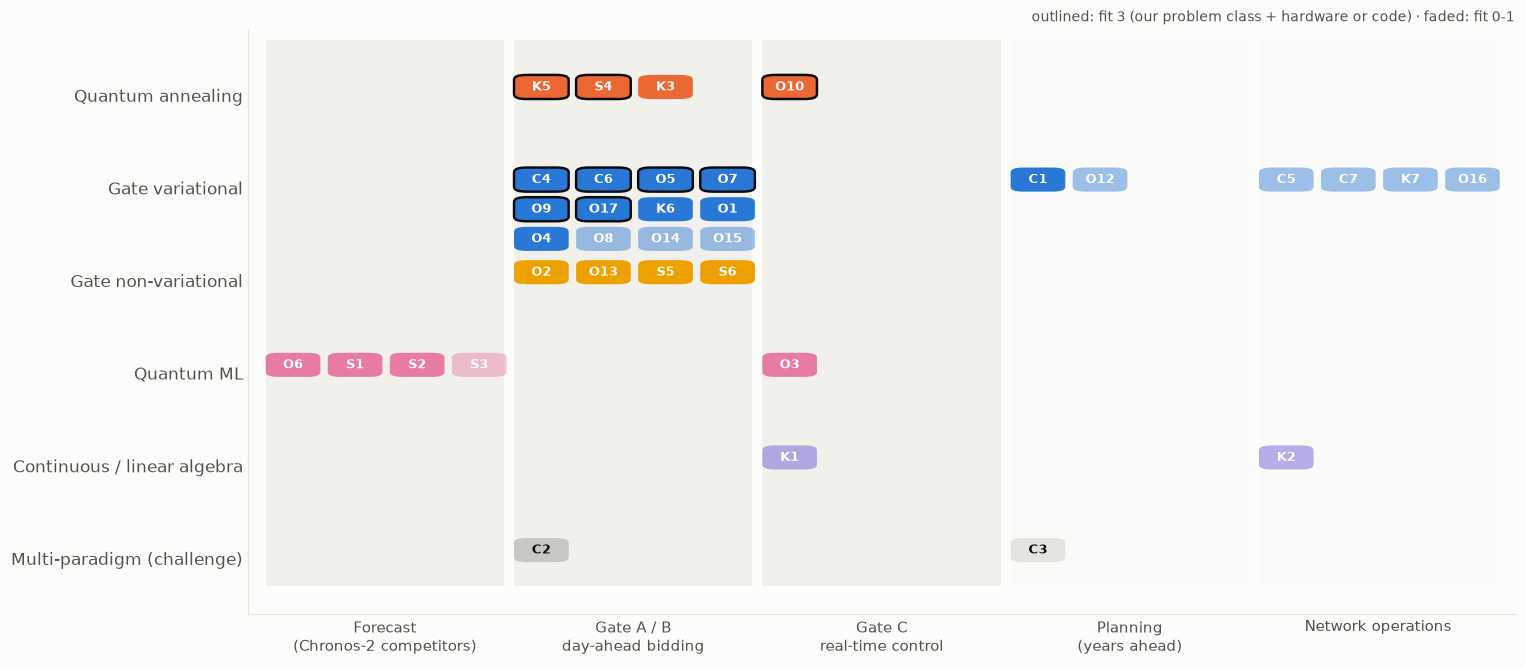

stage
Day-ahead bidding & scheduling    C2 C4 C6 K3 K5 K6 O1 O2 O4 O5 O7 O8 O9 O13 O14...
Forecasting                                                             O6 S1 S2 S3
Network operations                                                  C5 C7 K2 K7 O16
Out of scope                                                                     C8
Planning                                                                  C1 C3 O12
Real-time control                                                         K1 O3 O10
Survey                                                                 K4 K8 K9 O11


In [3]:
lanes = ['Forecasting', 'Day-ahead bidding & scheduling', 'Real-time control', 'Planning', 'Network operations']
lab = ['Forecast\n(Chronos-2 competitors)', 'Gate A / B\nday-ahead bidding', 'Gate C\nreal-time control', 'Planning\n(years ahead)', 'Network operations']
pars = [p for p in PAR if p not in ('Out of scope',)]
fig, ax = plt.subplots(figsize=(14, 6.2))
for j in range(len(lanes)):
    ax.add_patch(mp.Rectangle((j - .48, -.6), .96, len(pars) - .1, fc='#f1f0ea' if j < 3 else '#fafaf8', ec='none', zorder=0))
for i, p in enumerate(pars):
    for j, l in enumerate(lanes):
        g = M[(M.paradigm == p) & (M.stage == l)].sort_values('fit', ascending=False)
        for k, (_, r) in enumerate(g.iterrows()):
            xx = j - .38 + (k % 4) * .25; yy = i + (k // 4) * .32 - .1
            ax.add_patch(mp.FancyBboxPatch((xx - .1, yy - .12), .22, .26, boxstyle='round,pad=0,rounding_size=.05', fc=PAR[p], ec=INK if r.fit == '3' else 'none', lw=1.6,
                                           alpha=1 if r.fit >= '2' else .45, zorder=2))
            ax.text(xx + .01, yy + .01, r.id, ha='center', va='center', fontsize=8.5, color='white' if p != 'Multi-paradigm (challenge)' else INK, zorder=3, weight='bold')
ax.set_xticks(range(len(lanes)), lab, fontsize=10); ax.set_yticks(range(len(pars)), pars); ax.set_xlim(-.55, len(lanes) - .45); ax.set_ylim(len(pars) - .4, -.7)
ax.grid(False); ax.tick_params(length=0)
ax.set_title('outlined: fit 3 (our problem class + hardware or code) · faded: fit 0-1', loc='right', fontsize=9, color=INK2)
plt.tight_layout(); plt.show()
print(M.groupby('stage').id.apply(lambda s: ' '.join(s)).to_string())

## 3 · Real-hardware evidence
IBM carries the largest gate-model runs (150-156 qubits); D-Wave the annealing ones. No entry ran on IQM or Pasqal, the platforms we plan next to IBM.

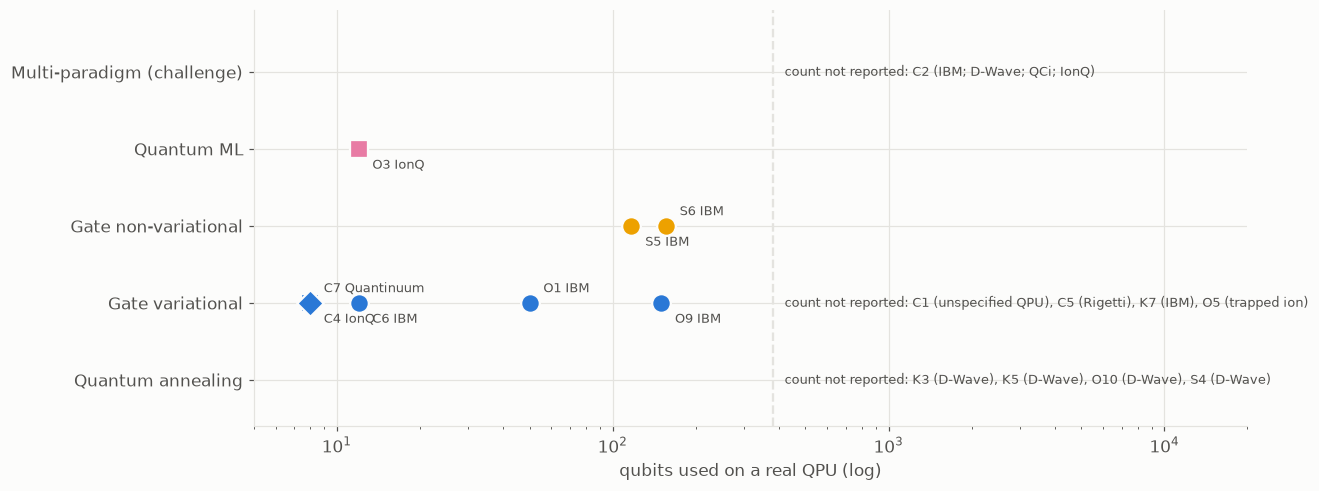

ran on a QPU: 17 of 40 | IQM: 0 | Pasqal: 0


In [4]:
hw = M[~M.hardware.isin(['', 'none (simulated)', 'none (ideal simulation)', 'none (simulated QPUs)', 'none (hardware-compatible)', 'none'])].copy()
hw['q'] = pd.to_numeric(hw.hw_qubits, errors='coerce')
vend = {'IBM': 'o', 'IonQ': 's', 'trapped ion': 's', 'Quantinuum': 'D', 'Rigetti': '^', 'D-Wave': 'P', 'unspecified QPU': 'X', 'IBM; D-Wave; QCi; IonQ': '*'}
pars = [p for p in PAR if p in set(hw.paradigm)]
fig, ax = plt.subplots(figsize=(12, 4.6))
seen = {}
for _, r in hw[hw.q.notna()].sort_values('q').iterrows():
    yy = pars.index(r.paradigm); n = seen[r.paradigm] = seen.get(r.paradigm, -1) + 1
    ax.scatter(r.q, yy, s=150, marker=vend.get(r.hardware, 'o'), color=PAR[r.paradigm], edgecolor=SURF, linewidth=1.5, zorder=3)
    ax.annotate(f"{r.id} {r.hardware}", (r.q, yy), xytext=(9, 7 if n % 2 else -13), textcoords='offset points', fontsize=8.5, color=INK2)
for p_, g_ in hw[hw.q.isna()].groupby('paradigm'):  # ran on a QPU, qubit count not reported: one line per row
    ax.text(420, pars.index(p_), 'count not reported: ' + ', '.join(f'{r.id} ({r.hardware})' for _, r in g_.iterrows()), va='center', fontsize=8.5, color=INK2)
ax.axvline(380, color=GRID, lw=1.5, ls='--')
ax.set_xscale('log'); ax.set_xlim(5, 20000); ax.set_yticks(range(len(pars)), pars); ax.set_ylim(-.6, len(pars) - .2)
ax.set_xlabel('qubits used on a real QPU (log)'); plt.tight_layout(); plt.show()
print('ran on a QPU:', len(hw), 'of', len(M), '| IQM:', int(M.hardware.str.contains('IQM').sum()), '| Pasqal:', int(M.hardware.str.contains('Pasqal').sum()))

## 4 · How many decisions fit on how many qubits
One qubit per binary sits on the diagonal. Pauli correlation encoding packs 10,296 decisions on 14 qubits (simulated); partitioning splits 1,710 across 50-qubit pieces.

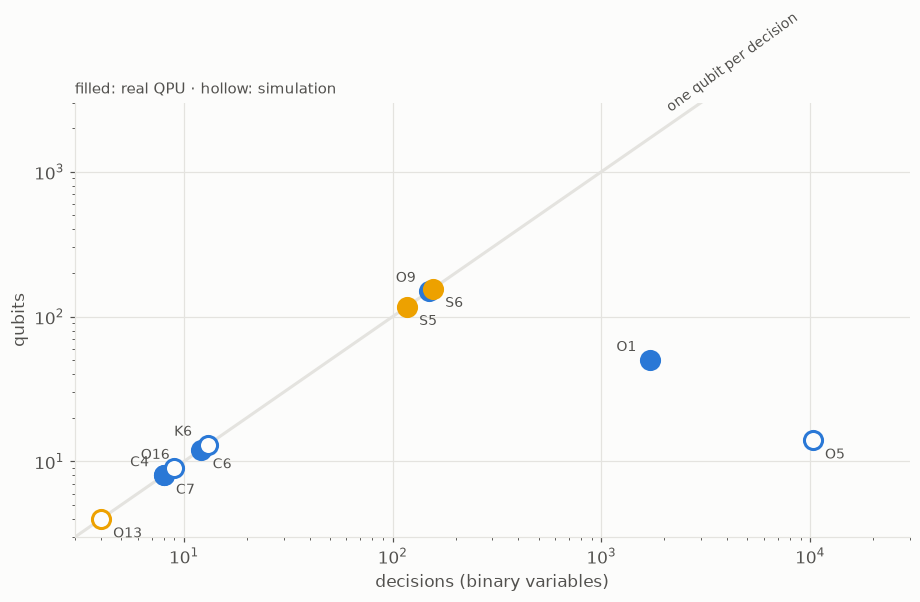

 id                                        encoding  decisions  qubits                hardware
O13                                    Penalty QUBO        4.0     4.0        none (simulated)
 C4                     Penalty QUBO + slack qubits        8.0     8.0                    IonQ
 C7                                    Penalty QUBO        8.0     8.0              Quantinuum
O16                                    Penalty QUBO        9.0     9.0        none (simulated)
 C6        Constraint-preserving mixer (XY + Dicke)       12.0    12.0                     IBM
 K6                                    Penalty QUBO       13.0    13.0 none (ideal simulation)
 S5                                    Penalty QUBO      117.0   117.0                     IBM
 O9 Constraint-biased (copula mixer + biased start)      150.0   150.0                     IBM
 S6                             Higher-order binary      156.0   156.0                     IBM
 O1              Penalty QUBO (max-weight matching

In [5]:
S = M[(M.vars != '') & (M.qubits_used != '')].copy(); S['v'] = S.vars.astype(float); S['q'] = S.qubits_used.astype(float)
fig, ax = plt.subplots(figsize=(8.5, 5.6)); xs = np.array([3, 3e4]); ax.plot(xs, xs, color=GRID, lw=2, zorder=1); ax.text(2e3, 2.6e3, 'one qubit per decision', rotation=36, fontsize=9, color=INK2)
for n, (_, r) in enumerate(S.sort_values('v').iterrows()):
    real = r.hw_qubits != ''  # filled only when this size itself ran on a QPU (O5's 10,296 was simulated; its trapped-ion run was small)
    ax.scatter(r.v, r.q, s=140, color=PAR[r.paradigm] if real else SURF, edgecolor=PAR[r.paradigm], linewidth=2, zorder=3)
    ax.annotate(r.id, (r.v, r.q), xytext=(-22 if n % 2 else 8, 6 if n % 2 else -12), textcoords='offset points', fontsize=9, color=INK2)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(3, 3e4); ax.set_ylim(3, 3e3)
ax.set_xlabel('decisions (binary variables)'); ax.set_ylabel('qubits'); ax.set_title('filled: real QPU · hollow: simulation', loc='left', fontsize=10, color=INK2)
plt.tight_layout(); plt.show()
print(S[['id', 'encoding', 'v', 'q', 'hardware']].rename(columns={'v': 'decisions', 'q': 'qubits'}).sort_values('decisions').to_string(index=False))

## 5 · What they were compared against, and what came out
Against a commercial solver the best reported outcome is *near Gurobi* (O9, IBM hardware) or a simulated win (K1). Against random sampling, one careful study finds no gain (K6).

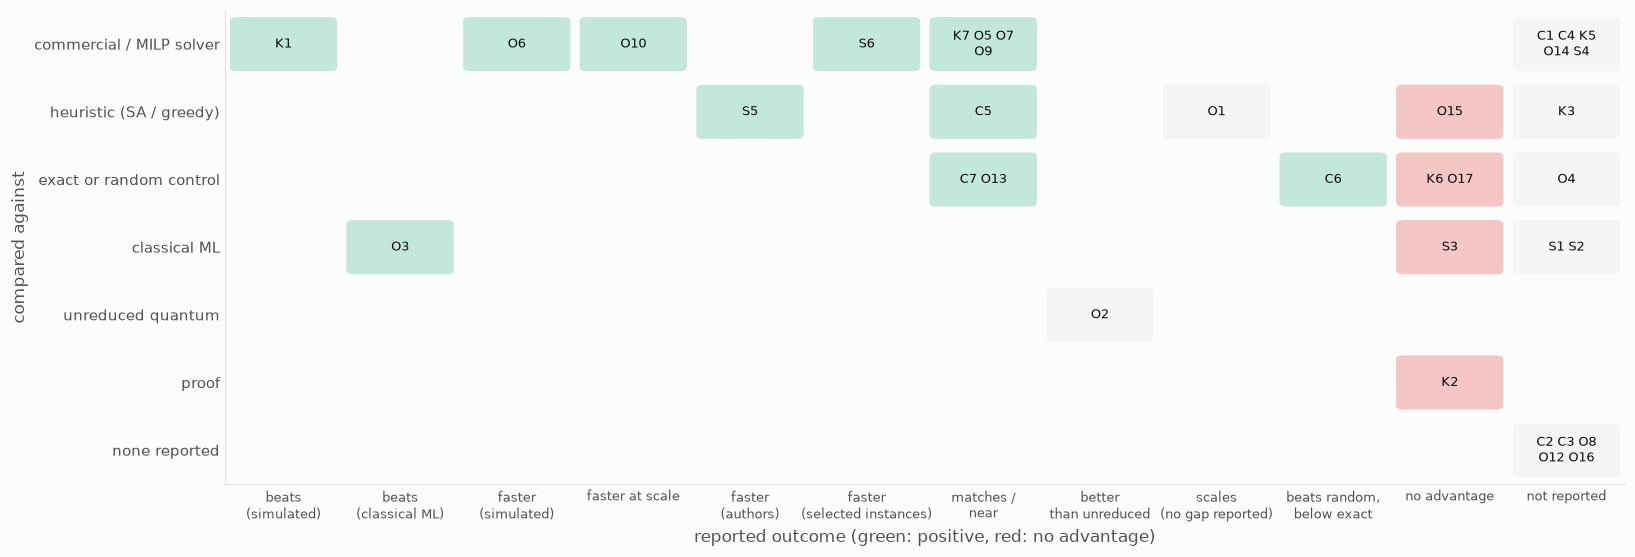

In [6]:
bc = {'C4': 'commercial / MILP solver', 'C6': 'exact or random control', 'C7': 'exact or random control', 'K1': 'commercial / MILP solver', 'K2': 'proof',
      'K5': 'commercial / MILP solver', 'K6': 'exact or random control', 'K7': 'commercial / MILP solver', 'O1': 'heuristic (SA / greedy)', 'O2': 'unreduced quantum',
      'O3': 'classical ML', 'O4': 'exact or random control', 'O5': 'commercial / MILP solver', 'O6': 'commercial / MILP solver', 'O7': 'commercial / MILP solver',
      'O9': 'commercial / MILP solver', 'O10': 'commercial / MILP solver', 'O13': 'exact or random control', 'O14': 'commercial / MILP solver',
      'O15': 'heuristic (SA / greedy)', 'O17': 'exact or random control', 'S1': 'classical ML', 'S2': 'classical ML', 'S3': 'classical ML',
      'S4': 'commercial / MILP solver', 'S5': 'heuristic (SA / greedy)', 'S6': 'commercial / MILP solver', 'C5': 'heuristic (SA / greedy)', 'C1': 'commercial / MILP solver', 'K3': 'heuristic (SA / greedy)'}
oc = {'C6': 'beats random, below exact', 'C7': 'matches / near', 'K1': 'beats (simulated)', 'K2': 'no advantage', 'K6': 'no advantage', 'K7': 'matches / near',
      'O1': 'scales (no gap reported)', 'O2': 'better than unreduced', 'O3': 'beats (classical ML)', 'O5': 'matches / near', 'O6': 'faster (simulated)', 'O7': 'matches / near',
      'O9': 'matches / near', 'O10': 'faster at scale', 'O13': 'matches / near', 'O15': 'no advantage', 'O17': 'no advantage', 'S3': 'no advantage',
      'S5': 'faster (authors)', 'S6': 'faster (selected instances)', 'C5': 'matches / near'}
M['bclass'] = M.id.map(bc).fillna('none reported'); M['oclass'] = M.id.map(oc).fillna('not reported')
rows = ['commercial / MILP solver', 'heuristic (SA / greedy)', 'exact or random control', 'classical ML', 'unreduced quantum', 'proof', 'none reported']
cols = ['beats (simulated)', 'beats (classical ML)', 'faster (simulated)', 'faster at scale', 'faster (authors)', 'faster (selected instances)', 'matches / near',
        'better than unreduced', 'scales (no gap reported)', 'beats random, below exact', 'no advantage', 'not reported']
X = M[M.paradigm != 'Out of scope']; tab = X.groupby(['bclass', 'oclass']).id.apply(lambda s: ' '.join(s))
fig, ax = plt.subplots(figsize=(15, 5.2)); ax.set_xlim(-.5, len(cols) - .5); ax.set_ylim(len(rows) - .5, -.5)
for i, r_ in enumerate(rows):
    for j, c_ in enumerate(cols):
        s = tab.get((r_, c_), '')
        if s:
            good = c_.startswith(('beats', 'faster', 'matches')); bad = c_ == 'no advantage'
            ax.add_patch(mp.FancyBboxPatch((j - .46, i - .4), .92, .8, boxstyle='round,pad=0,rounding_size=.06', fc='#1baf7a' if good else '#e34948' if bad else '#e4e3df', alpha=.25 if not bad else .3, ec='none'))
            ids_ = s.split(); s2 = '\n'.join(' '.join(ids_[k:k + 3]) for k in range(0, len(ids_), 3))
            ax.text(j, i, s2, ha='center', va='center', fontsize=8.5)
ax.set_xticks(range(len(cols)), [c.replace(' (', '\n(').replace(', ', ',\n').replace(' / ', ' /\n').replace('better than', 'better\nthan') for c in cols], fontsize=8.5); ax.set_yticks(range(len(rows)), rows, fontsize=9.5)
ax.grid(False); ax.tick_params(length=0); ax.set_xlabel('reported outcome (green: positive, red: no advantage)'); ax.set_ylabel('compared against')
plt.tight_layout(); plt.show()

## 6 · Fit to KratTrade, and the shortlist per stage
Fit 3 = our problem class (storage / scheduling / two-stage day-ahead + real time) and hardware evidence or code; 2 = reusable method; 1 = idea only.

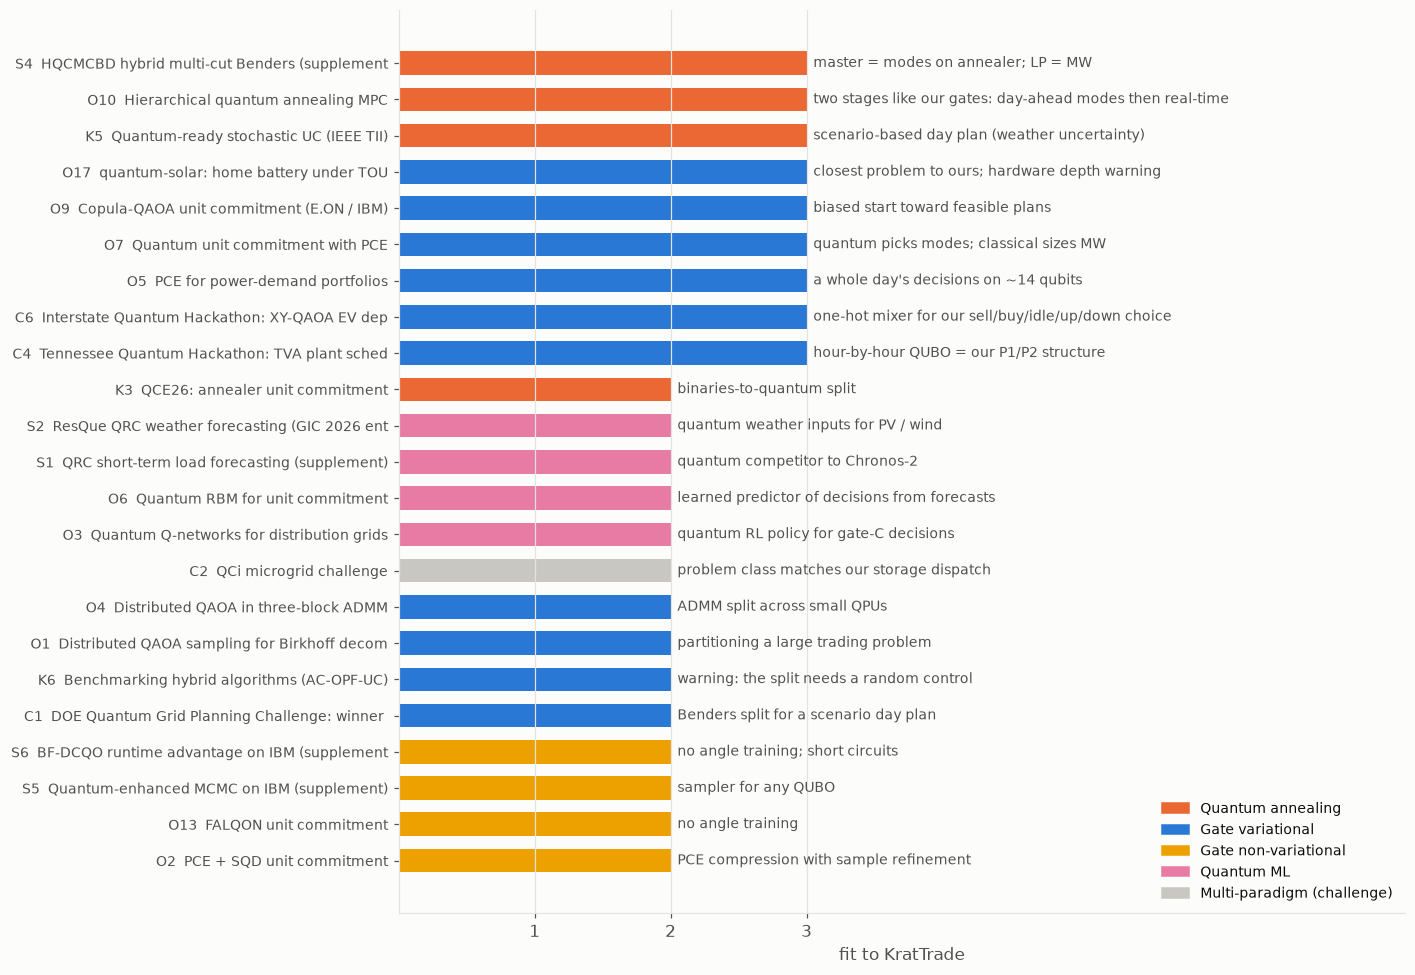

Shortlist (fit 3) by stage:
stage
Day-ahead bidding & scheduling    C4 hour-by-hour QAOA, C6 XY-mixer QAOA, O5 PCE...
Real-time control                 O10 D-Wave QA day-ahead on/off + short-term re...

Forecasting candidates (none in the doc itself):
id                                   algorithm                              outcome
O6 qRBM predicts UC patterns + affine recovery 99.96 % less time; 276x fewer qubits
S1                 quantum reservoir computing                         not reported
S2                 quantum reservoir computing                         not reported
S3                            QLSTM / le-QLSTM           classical models rank best


In [7]:
F = M[M.fit.isin(['2', '3'])].copy(); F['f'] = F.fit.astype(int)
F = F.sort_values(['f', 'paradigm']).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(13, 9))
for i, r in F.iterrows():
    ax.barh(i, r.f, color=PAR[r.paradigm], height=.65)
    ax.text(r.f + .05, i, f"{r.kt_role}", va='center', fontsize=9, color=INK2)
ax.set_yticks(range(len(F)), [f"{r.id}  {r['name'][:44]}" for _, r in F.iterrows()], fontsize=9); ax.set_xlim(0, 7.4); ax.set_xticks([1, 2, 3])
ax.set_xlabel('fit to KratTrade'); ax.grid(axis='y', visible=False)
ax.legend(handles=[mp.Patch(color=PAR[p], label=p) for p in PAR if p in set(F.paradigm)], loc='lower right', fontsize=9)
plt.tight_layout(); plt.show()
short = F[F.f == 3].groupby('stage').apply(lambda g: ', '.join(f"{r.id} {r.algorithm}" for _, r in g.iterrows()), include_groups=False)
fc = M[M.stage == 'Forecasting']
print('Shortlist (fit 3) by stage:'); print(short.to_string())
print('\nForecasting candidates (none in the doc itself):'); print(fc[['id', 'algorithm', 'outcome']].to_string(index=False))

## 7 · The catalogue, grouped by paradigm and pattern

In [8]:
pd.set_option('display.max_colwidth', 48); pd.set_option('display.width', 220)
for p in PAR:
    g = M[M.paradigm == p].sort_values(['group', 'id'])
    if len(g):
        print(f'\n=== {p} ({len(g)})')
        print(g[['id', 'group', 'algorithm', 'problem', 'hardware', 'hw_qubits', 'baseline', 'outcome', 'code']].to_string(index=False))


=== Quantum annealing (4)
 id                         group                                                                          algorithm                                    problem hardware hw_qubits         baseline                          outcome code
 K3 Binaries on QPU, MW classical                                             D-Wave picks units; dispatch classical               Unit commitment (<=30 buses)   D-Wave           classical repair                     not reported   no
 K5                 Decomposition D-Wave QA + hybrid CQM + quantum-inspired; divide-and-conquer over 27730 scenarios  Stochastic unit commitment (IEEE 118-bus)   D-Wave                Gurobi / SA                     not reported   no
O10                 Decomposition                                 D-Wave QA day-ahead on/off + short-term refinement Household microgrids with hydrogen storage   D-Wave                     Gurobi QA preferable as households grow   no
 S4                 Decomposition    